# Before the workshop: package setup

In **Colab**, run this cell before importing packages. Locally, use the prepared `.venv-gssc` kernel and follow `README.rst`. This installs the publication's repository at a fixed revision.

In [1]:
import subprocess
import sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/jshanna100/gssc.git@2da29b0715242f3a76b0daab2ba7d593a91eb7f8",
        "mne>=1.7,<2", "torch>=2.6,<3", "pooch>=1.8,<2", "ipywidgets>=8,<9",
    ])
else:
    print("Local mode: select .venv-gssc as the kernel.")

Local mode: select workshop/.venv-gssc as the kernel.


# Getting started with GSSC
**Core: 15 minutes. Optional sequential replay: 10 minutes.**

We use the original repository accompanying Hanna & Floel (2023):
https://github.com/jshanna100/gssc
https://doi.org/10.3389/fninf.2023.1086634

By the end, you can load EEG/EOG, predict sleep stages, inspect probabilities,
and flag uncertain epochs. An optional extension demonstrates the documented
epoch-by-epoch API. This is a recorded-data lesson with no stimulation control.

**Predict:** will every 30-second epoch be equally easy to classify?
Complete installation before the timed session; see README.rst.

In [2]:
import importlib.metadata as metadata
import json
import os
from pathlib import Path
import sys
from time import perf_counter

GSSC_COMMIT = "2da29b0715242f3a76b0daab2ba7d593a91eb7f8"
GSSC_REPOSITORY = "https://github.com/jshanna100/gssc"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Use the existing data cache locally; a standalone notebook also works in Colab.
if "__file__" in globals():
    WORKSHOP = Path(__file__).resolve().parents[1]
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    WORKSHOP = next((p for p in candidates if (p / "requirements.txt").is_file()
                     and (p / "gssc_workshop").is_dir()), Path.cwd() / "gssc_demo")
WORKSHOP.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(WORKSHOP / ".mplconfig-gssc"))

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pooch
import torch
from gssc.infer import EEGInfer
from IPython.display import display

# CPU is sufficient for this small example; no NVIDIA GPU is required.
torch.set_num_threads(2)
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT = WORKSHOP / "outputs" / "gssc_workshop"
OUT.mkdir(parents=True, exist_ok=True)
STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])
PROBABILITY_COLUMNS = [f"P_{stage}" for stage in STAGE_NAMES]
versions = {name: metadata.version(name) for name in ["gssc", "torch", "mne", "numpy", "scipy", "pandas"]}
source_info = json.loads(metadata.distribution("gssc").read_text("direct_url.json") or "{}")
installed_commit = source_info.get("vcs_info", {}).get("commit_id")
if installed_commit != GSSC_COMMIT:
    raise RuntimeError("Install the pinned GitHub revision using this lesson's requirements.txt; see README.rst.")
print("Python:", sys.executable)
print("Verified GSSC repository revision:", installed_commit)
print("Installed packages:", versions)
print("Results:", OUT)

Python: <repository>/.venv-gssc/bin/python
Verified GSSC repository revision: 2da29b0715242f3a76b0daab2ba7d593a91eb7f8
Installed packages: {'gssc': '0.0.9', 'torch': '2.15.0', 'mne': '1.13.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.1'}
Results: <repository>/outputs/gssc_workshop


## 2. Meet the recording
We reuse the **49-minute nap** from the YASA workshop. This is sample data,
not a participant undergoing TIS. C4 (EEG) and EOG1 (eye movements) are inputs.
The supplied reference stages are used only to compare results.

MNE stores signals in **volts**. We request **microvolts** for EEG plots.
**Try:** identify the sampling rate, recording duration and available channels.

In [3]:
samples = pooch.create(
    path=WORKSHOP / "data",
    base_url="https://zenodo.org/records/14564285/files/",
    registry={
        "sub-02_mne_raw.fif": "md5:eb9360c29f21092834bfd67079b3c57e",
        "sub-02_hypno_30s.txt": "md5:bcf75ac8180cdc68c5a6d20f921d1473",
    },
)
raw = mne.io.read_raw_fif(samples.fetch("sub-02_mne_raw.fif"), preload=True, verbose=False)
reference = np.loadtxt(samples.fetch("sub-02_hypno_30s.txt"), dtype=str)
reference = np.array([{"W": "WAKE", "R": "REM"}.get(stage, stage) for stage in reference])
sf = float(raw.info["sfreq"])
assert np.isclose(raw.n_times / sf, len(reference) * 30)
print("Channels:", raw.ch_names)
print(f"Sampling rate: {sf:g} Hz | Duration: {raw.n_times / sf / 60:.1f} min")
display(pd.Series(reference).value_counts().rename("Reference epochs"))

Channels: ['F3', 'F4', 'C3', 'C4', 'O1', 'O2', 'EOG1', 'EOG2', 'EMG1']
Sampling rate: 100 Hz | Duration: 49.0 min


WAKE    36
N2      31
N3      22
N1       9
Name: Reference epochs, dtype: int64

## 3. Run GSSC on the recorded nap
We use the publication's `EEGInfer` API with one explicit EEG/EOG combination.
GSSC's five classes are **Wake, N1, N2, N3, REM**.

The core example uses the full recording for filtering and normalization.
It is an **offline introduction**, not a demonstration of live processing.
The bundled context GRU is bidirectional: predictions can use preceding AND
following epochs. `chunk_n=8` only batches the signal encoder; all epoch
representations then enter the context GRU together. It is not an eight-epoch
context window. `filter=False` below skips an extra filter, not the context GRU.
**Where is the GRU called?** The marked `classifier.mne_infer(...)` line below
enters the wrapper. Inside GSSC it calls `con_net(reps, hidden)` once on the
full sequence of epoch representations, starting with zero hidden state.
The actual PyTorch operation is `self.gru(input, hidden)` inside
[`SleepGRU.forward`](https://github.com/jshanna100/gssc/blob/2da29b0715242f3a76b0daab2ba7d593a91eb7f8/gssc/networks.py#L333).
We explicitly create 30-second epochs to preserve the final complete epoch.
The original `raw` is kept for later signal inspection and replay.

In [4]:
model_input = raw.copy().pick(["C4", "EOG1"])
model_input.filter(l_freq=0.3, h_freq=30, verbose=False)
epochs = mne.make_fixed_length_epochs(model_input, duration=30, preload=True, verbose=False)
assert len(epochs) == len(reference)
classifier = EEGInfer(use_cuda=False, chunk_n=8)  # Loads models; no GRU inference yet.
started = perf_counter()
# GRU call via this wrapper: BIDIRECTIONAL OFFLINE CONTEXT.
# Internally: y, hidden = con_net(reps, hidden), with ALL epochs in reps.
# Prediction for epoch t can use preceding AND following epochs.
# chunk_n=8 only batches the encoder; it does not select forward inference.
stage_codes, start_seconds, probabilities = classifier.mne_infer(
    epochs, eeg=["C4"], eog=["EOG1"], eeg_drop=False, eog_drop=False, filter=False
)
batch_seconds = perf_counter() - started
predicted = STAGE_NAMES[stage_codes]
assert probabilities.shape == (len(reference), 5)
assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1)
assert np.array_equal(stage_codes, probabilities.argmax(axis=1))
assert np.allclose(start_seconds, np.arange(len(reference)) * 30)
table = pd.DataFrame({
    "Epoch": np.arange(len(reference)), "Start_s": start_seconds,
    "Reference": reference, "Predicted": predicted,
    "Max_probability": probabilities.max(axis=1),
})
table[PROBABILITY_COLUMNS] = probabilities
agreement = float(np.mean(reference == predicted))
print(f"Computed {len(table)} epochs in {batch_seconds:.2f} seconds on this computer.")
print(f"Agreement with this nap's reference: {100 * agreement:.1f}%")
display(table.head().round(3))

Running without CUDA on CPU. Speed will be suboptimal.
Inferring permutation 1 of 1


Computed 98 epochs in 0.26 seconds on this computer.
Agreement with this nap's reference: 92.9%


,Epoch,Start_s,Reference,Predicted,Max_probability,P_WAKE,P_N1,P_N2,P_N3,P_REM
0,0,0,WAKE,WAKE,0.934,0.934,0.002,0.030,0.020,0.015
1,1,30,WAKE,WAKE,0.991,0.991,0.001,0.003,0.001,0.005
2,2,60,WAKE,WAKE,0.994,0.994,0.002,0.001,0.000,0.003
3,3,90,WAKE,WAKE,0.993,0.993,0.003,0.001,0.000,0.003
4,4,120,WAKE,WAKE,0.991,0.991,0.005,0.002,0.000,0.002


## 4. Inspect the hypnograms
Wake is at the top and N3 at the bottom. Look for transitions and disagreements.
This nap contains **no reference REM**, so it cannot establish REM accuracy.
Agreement on this teaching recording is not a general performance estimate.

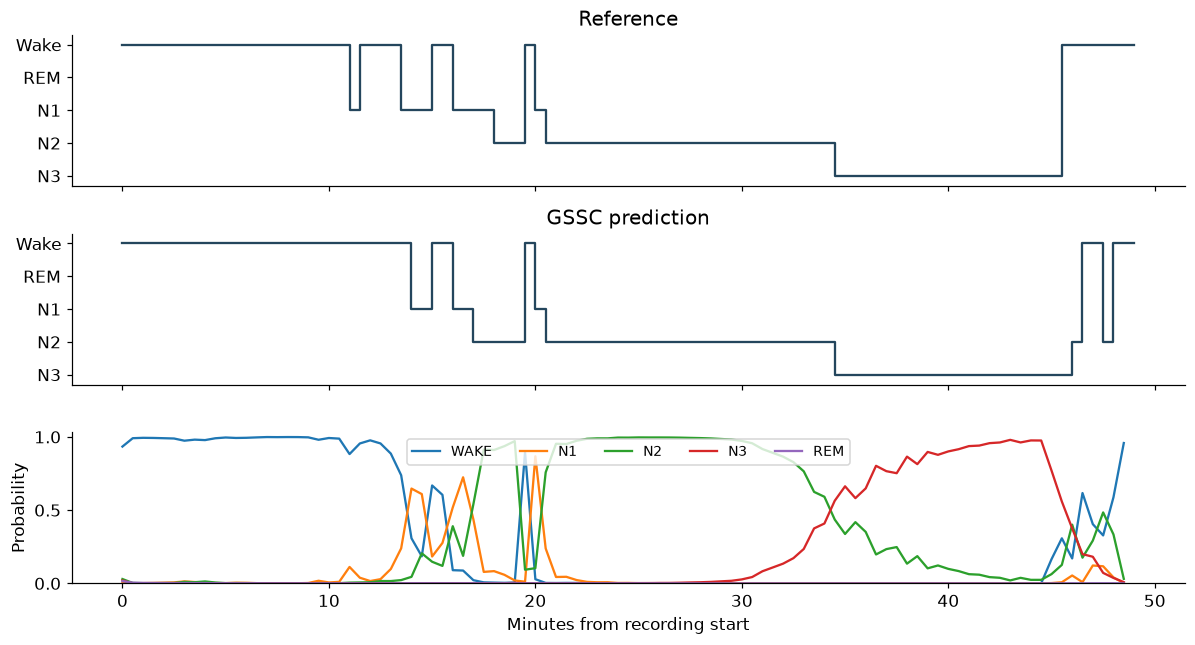

In [5]:
positions = {"N3": 0, "N2": 1, "N1": 2, "REM": 3, "WAKE": 4}
edges_min = np.arange(len(table) + 1) * 0.5
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, labels, title in zip(axes[:2], [reference, predicted], ["Reference", "GSSC prediction"]):
    y = [positions[stage] for stage in labels]
    ax.step(edges_min, [*y, y[-1]], where="post", color="#24465D")
    ax.set(yticks=range(5), yticklabels=["N3", "N2", "N1", "REM", "Wake"],
           ylim=(-0.3, 4.3), title=title)
for column, stage in zip(PROBABILITY_COLUMNS, STAGE_NAMES):
    axes[2].plot(table.Start_s / 60, table[column], label=stage)
axes[2].set(xlabel="Minutes from recording start", ylabel="Probability", ylim=(0, 1.03))
axes[2].legend(ncol=5, loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "01_hypnograms_and_probabilities.png", dpi=160)
plt.show()

## 5. Try it: change a review cutoff
`Max_probability` is the model's highest stage probability. It describes
confidence in the prediction; it does not establish correctness.

**Predict first:** will moving the cutoff from **0.6 to 0.8** flag more epochs?
Run the helper cell, then change only `review_cutoff` in the next cell.

In [6]:
def review_predictions(cutoff=0.6):
    if not 0 <= cutoff <= 1:
        raise ValueError("Choose a cutoff between 0 and 1.")
    reviewed = table.copy()
    reviewed["Flag_for_review"] = reviewed.Max_probability < cutoff
    fig, ax = plt.subplots(figsize=(11, 2.6))
    ax.plot(reviewed.Start_s / 60, reviewed.Max_probability, color="#24465D")
    flagged = reviewed.Flag_for_review
    ax.scatter(reviewed.loc[flagged, "Start_s"] / 60,
               reviewed.loc[flagged, "Max_probability"], color="#C16A32", zorder=3)
    ax.axhline(cutoff, color="#C16A32", linestyle="--")
    ax.set(xlabel="Time (minutes)", ylabel="Max probability", ylim=(0, 1.03))
    fig.tight_layout()
    fig.savefig(OUT / "02_confidence_review.png", dpi=160)
    plt.show()
    print(f"{int(flagged.sum())} of {len(reviewed)} epochs flagged; stages unchanged.")
    display(reviewed.loc[flagged, ["Epoch", "Reference", "Predicted", "Max_probability"]].round(3))
    return reviewed

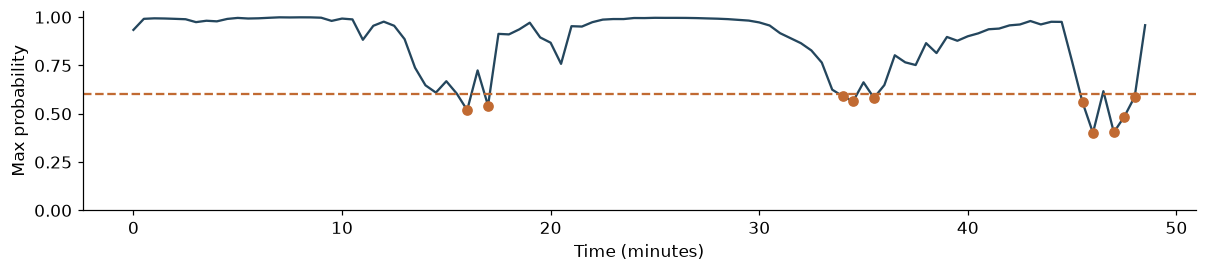

10 of 98 epochs flagged; stages unchanged.


,Epoch,Reference,Predicted,Max_probability
32,32,N1,N1,0.519
34,34,N1,N2,0.542
68,68,N2,N2,0.591
69,69,N3,N3,0.564
71,71,N3,N3,0.582
91,91,WAKE,N3,0.559
92,92,WAKE,N2,0.401
94,94,WAKE,WAKE,0.404
95,95,WAKE,N2,0.484
96,96,WAKE,WAKE,0.588


In [7]:
review_cutoff = 0.6
review_table = review_predictions(review_cutoff)

## 6. Look at the signals behind one prediction
Start with the least-confident epoch. Try a different `epoch_to_inspect` next.
A confident prediction can also be wrong. What evidence would you review?

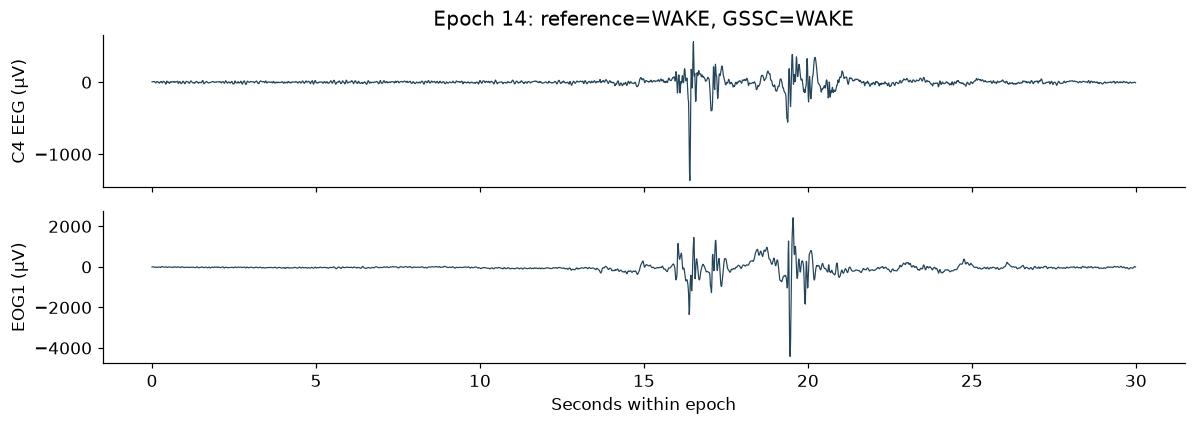

,Epoch,Start_s,Reference,Predicted,Max_probability,P_WAKE,P_N1,P_N2,P_N3,P_REM
14,14,420,WAKE,WAKE,0.999,0.999,0.001,0.0,0.0,0.0


In [8]:
def inspect_epoch(epoch):
    epoch = int(epoch)
    if not 0 <= epoch < len(table):
        raise ValueError(f"Choose an epoch from 0 to {len(table) - 1}.")
    start, stop = int(epoch * 30 * sf), int((epoch + 1) * 30 * sf)
    signals_uv = raw.get_data(picks=["C4", "EOG1"], start=start, stop=stop) * 1e6
    fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
    for ax, values, label in zip(axes, signals_uv, ["C4 EEG", "EOG1"]):
        ax.plot(np.arange(len(values)) / sf, values, color="#24465D", linewidth=0.8)
        ax.set_ylabel(label + " (µV)")
    axes[0].set_title(f"Epoch {epoch}: reference={reference[epoch]}, GSSC={predicted[epoch]}")
    axes[-1].set_xlabel("Seconds within epoch")
    fig.tight_layout()
    fig.savefig(OUT / "03_example_epoch.png", dpi=160)
    plt.show()
    display(table.iloc[[epoch]].round(3))

epoch_to_inspect = int(table.Max_probability.argmax())  # CHANGE ME, e.g. to 40.
inspect_epoch(epoch_to_inspect)

## 7. Save the result and discuss
Keep predictions, probabilities and the supplied reference in distinct columns.
These predicted stages could be reviewed and passed to YASA's offline event
detectors. The original continuous EEG is also needed for event detection.

In [9]:
review_table.to_csv(OUT / "gssc_recorded_predictions.csv", index=False)
summary = {
    "repository": GSSC_REPOSITORY, "commit": installed_commit, "versions": versions,
    "recording": "sub-02_mne_raw.fif", "inputs": ["C4", "EOG1"],
    "epoch_seconds": 30, "n_epochs": len(table), "agreement_percent": 100 * agreement,
    "reference_has_REM": bool(np.any(reference == "REM")), "review_cutoff": review_cutoff,
    "mode": "recorded EEGInfer; full-record preprocessing", "batch_seconds": batch_seconds,
}
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT / "gssc_recorded_predictions.csv")

Saved: <repository>/outputs/gssc_workshop/gssc_recorded_predictions.csv


## Optional comparison: GSSC and YASA on the same epochs
Each matrix shows counts and percentages within its ROW stage. Rows are the
supplied reference unless explicitly labelled YASA; columns are predictions.
A YASA-versus-GSSC matrix describes agreement between models, not accuracy.
Empty reference REM rows are marked n/a because this nap has no reference REM.

Both models use C4 EEG + EOG1, without EMG or demographics. A separate YASA run
exports these predictions, so YASA need not be installed in the GSSC environment.
Run export_yasa_comparison.py with the YASA environment to prepare that export.
Exact epoch IDs, times, reference labels, recording metadata AND channel names
are checked before comparison. The original three-channel YASA results are
kept separately. Each classifier retains its own preprocessing and pretrained
model; matching channels does not make the preprocessing identical.

In [10]:
"""Aligned, five-stage comparisons for the GSSC teaching recording."""

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])


def _stage_labels(values, name):
    labels = np.asarray(values, dtype=str)
    if labels.ndim != 1:
        raise ValueError(f"{name} must be a one-dimensional sequence of stages.")
    labels = np.char.upper(np.char.strip(labels))
    labels = np.array([{"W": "WAKE", "R": "REM"}.get(x, x) for x in labels])
    unknown = sorted(set(labels) - set(STAGE_NAMES))
    if unknown:
        raise ValueError(f"{name} contains unsupported stage labels: {unknown}.")
    return labels


def load_yasa_comparison(csv_path, choices_path, epochs, start_seconds, reference,
                         expected_inputs=("C4", "EOG1")):
    """Load matching YASA results, rejecting any epoch/time/reference mismatch.

    CSV columns are Epoch, Start_min, Reference and Predicted. Metadata must
    identify sub-02_mne_raw.fif, 30-second epochs and the expected input channels.
    Missing CSVs are optional;
    present but incompatible results raise an error rather than being trimmed.
    """
    csv_path, choices_path = Path(csv_path), Path(choices_path)
    if not csv_path.is_file():
        print(f"YASA comparison skipped: no saved predictions at {csv_path}.")
        return None, None
    if not choices_path.is_file():
        raise ValueError(f"Cannot verify YASA provenance: metadata missing at {choices_path}.")
    try:
        choices = json.loads(choices_path.read_text())
    except (OSError, ValueError) as error:
        raise ValueError(f"Cannot read YASA comparison metadata: {choices_path}.") from error
    if not isinstance(choices, dict) or choices.get("sample") != "sub-02_mne_raw.fif":
        raise ValueError("YASA metadata must identify sample='sub-02_mne_raw.fif'.")
    if choices.get("epoch_seconds") != 30:
        raise ValueError("YASA comparison requires metadata epoch_seconds=30.")
    if not isinstance(choices.get("inputs"), list) or not choices["inputs"] or not all(
        isinstance(channel, str) for channel in choices["inputs"]
    ):
        raise ValueError("YASA metadata must list the input channel names in 'inputs'.")
    if choices["inputs"] != list(expected_inputs):
        raise ValueError(
            f"YASA inputs {choices['inputs']} do not match the required channels "
            f"{list(expected_inputs)}. Run export_yasa_comparison.py for this comparison."
        )
    table = pd.read_csv(csv_path)
    required = {"Epoch", "Start_min", "Reference", "Predicted"}
    if not required.issubset(table.columns):
        raise ValueError(f"YASA CSV is missing columns: {sorted(required - set(table.columns))}.")
    epochs, start_seconds = np.asarray(epochs), np.asarray(start_seconds, dtype=float)
    reference = _stage_labels(reference, "GSSC reference")
    if epochs.ndim != 1 or start_seconds.ndim != 1 or not (
        len(epochs) == len(start_seconds) == len(reference) == len(table)
    ):
        raise ValueError("YASA/GSSC epoch counts differ; rerun both on the same complete recording.")
    if not np.isfinite(start_seconds).all() or len(set(epochs.tolist())) != len(epochs):
        raise ValueError("Expected GSSC epoch IDs must be unique and start times finite.")
    try:
        saved_epochs = pd.to_numeric(table.Epoch, errors="raise").to_numpy()
        saved_starts = pd.to_numeric(table.Start_min, errors="raise").to_numpy() * 60
    except (TypeError, ValueError) as error:
        raise ValueError("YASA Epoch and Start_min columns must contain numeric values.") from error
    if not np.array_equal(saved_epochs, epochs):
        raise ValueError("YASA Epoch IDs/order do not match GSSC; results were not reordered or trimmed.")
    if not np.allclose(saved_starts, start_seconds, rtol=0, atol=1e-6):
        raise ValueError("YASA Start_min times do not align with GSSC 30-second epochs.")
    table["Reference"] = _stage_labels(table.Reference, "YASA reference")
    table["Predicted"] = _stage_labels(table.Predicted, "YASA predictions")
    if not np.array_equal(table.Reference.to_numpy(), reference):
        raise ValueError("YASA reference stages differ from GSSC; compare the same reference file.")
    return table, choices


def plot_confusion_panels(comparisons, output_path, note=None):
    """Plot counts and row percentages; return fixed-order count DataFrames.

    comparisons contains (row_name, row_labels, column_name, column_labels).
    Save a PNG and panelN_counts/row_percentages CSVs beside it. Empty reference
    rows have no denominator and display n/a, rather than an apparent 0% recall.
    """
    comparisons = list(comparisons)
    if not comparisons:
        raise ValueError("Supply at least one confusion-matrix comparison.")
    validated = []
    for row_name, rows, column_name, columns in comparisons:
        rows = _stage_labels(rows, row_name)
        columns = _stage_labels(columns, column_name)
        if len(rows) != len(columns) or not len(rows):
            raise ValueError(f"{row_name}/{column_name}: labels must have equal, nonzero length.")
        validated.append((row_name, rows, column_name, columns))
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, len(validated), figsize=(5.1 * len(validated), 5.2),
                             squeeze=False, constrained_layout=True)
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#f1f3f5")
    indices = {stage: i for i, stage in enumerate(STAGE_NAMES)}
    count_tables = []
    for panel, (ax, item) in enumerate(zip(axes[0], validated), start=1):
        row_name, rows, column_name, columns = item
        counts = np.zeros((5, 5), dtype=int)
        np.add.at(counts, ([indices[x] for x in rows], [indices[x] for x in columns]), 1)
        totals = counts.sum(axis=1, keepdims=True)
        percentages = np.divide(100.0 * counts, totals,
                                out=np.full((5, 5), np.nan), where=totals != 0)
        ax.imshow(np.ma.masked_invalid(percentages), cmap=cmap, vmin=0, vmax=100)
        for i in range(5):
            for j in range(5):
                value = percentages[i, j]
                label = f"{counts[i, j]}\n{value:.1f}%" if np.isfinite(value) else "0\nn/a"
                ax.text(j, i, label, ha="center", va="center", fontsize=9,
                        color="white" if np.isfinite(value) and value >= 60 else "#172b3a")
        correct, total = int(np.trace(counts)), len(rows)
        ax.set(xticks=np.arange(5), yticks=np.arange(5),
               xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES,
               xlabel=f"{column_name} (columns)", ylabel=f"{row_name} (rows)",
               title=f"{column_name} vs {row_name}\nAgreement: {correct}/{total} ({correct / total:.1%})")
        count_table = pd.DataFrame(counts, index=STAGE_NAMES, columns=STAGE_NAMES)
        percent_table = pd.DataFrame(percentages, index=STAGE_NAMES, columns=STAGE_NAMES)
        for table in (count_table, percent_table):
            table.index.name, table.columns.name = row_name, column_name
        stem = output_path.with_name(f"{output_path.stem}_panel{panel}")
        count_table.to_csv(stem.with_name(stem.name + "_counts.csv"))
        percent_table.to_csv(stem.with_name(stem.name + "_row_percentages.csv"), na_rep="n/a")
        count_tables.append(count_table)
    caption = "Cells: epoch count and row percentage; color: row percentage"
    fig.suptitle(f"{note}\n{caption}" if note else caption, fontsize=12)
    fig.savefig(output_path, dpi=160, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    return count_tables

YASA inputs: ['C4', 'EOG1'] | GSSC inputs: C4, EOG1
GSSC and YASA disagree on 10/98 epochs.


,Epoch,Start_s,Reference,GSSC_offline,YASA
29,29,870,N1,N1,N2
32,32,960,N1,N1,N2
34,34,1020,N1,N2,N1
39,39,1170,WAKE,WAKE,N2
51,51,1530,N2,N2,N1
68,68,2040,N2,N2,N3
90,90,2700,N3,N3,WAKE
91,91,2730,WAKE,N3,WAKE
92,92,2760,WAKE,N2,WAKE
95,95,2850,WAKE,N2,WAKE


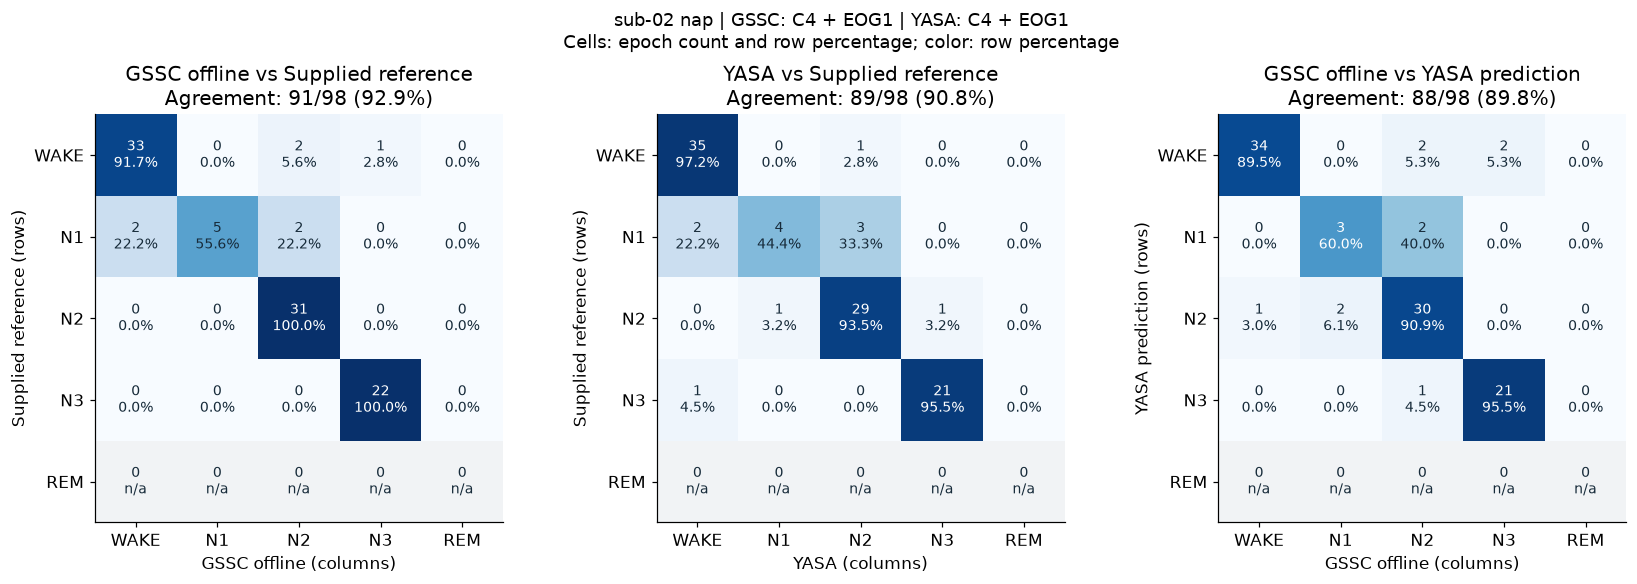

,Comparison,Matching_epochs,Total_epochs,Agreement_percent
0,GSSC offline vs reference,91,98,92.86
1,YASA vs reference,89,98,90.82
2,GSSC offline vs YASA,88,98,89.80


In [11]:
YASA_CSV = OUT / "yasa_c4_eog1/staging_predictions.csv"
YASA_CHOICES = YASA_CSV.with_name("analysis_choices.json")
yasa_comparison, yasa_choices = load_yasa_comparison(
    YASA_CSV, YASA_CHOICES, table.Epoch.to_numpy(), start_seconds, reference
)
comparison_table = pd.DataFrame({
    "Epoch": table.Epoch, "Start_s": start_seconds, "Reference": reference,
    "GSSC_offline": predicted,
})
recorded_panels = [("Supplied reference", reference, "GSSC offline", predicted)]
comparison_metrics = [{"Comparison": "GSSC offline vs reference", "Matching_epochs": int(np.sum(reference == predicted)),
                       "Total_epochs": len(reference), "Agreement_percent": 100 * agreement}]
if yasa_comparison is not None:
    yasa_predicted = yasa_comparison.Predicted.to_numpy()
    comparison_table["YASA"] = yasa_predicted
    recorded_panels += [("Supplied reference", reference, "YASA", yasa_predicted),
                        ("YASA prediction", yasa_predicted, "GSSC offline", predicted)]
    for name, left, right in [("YASA vs reference", reference, yasa_predicted),
                              ("GSSC offline vs YASA", yasa_predicted, predicted)]:
        matches = int(np.sum(left == right))
        comparison_metrics.append({"Comparison": name, "Matching_epochs": matches,
                                   "Total_epochs": len(reference), "Agreement_percent": 100 * matches / len(reference)})
    print("YASA inputs:", yasa_choices["inputs"], "| GSSC inputs: C4, EOG1")
    disagreements = comparison_table.loc[comparison_table.GSSC_offline != comparison_table.YASA]
    disagreements.to_csv(OUT / "gssc_yasa_disagreements.csv", index=False)
    print(f"GSSC and YASA disagree on {len(disagreements)}/{len(reference)} epochs.")
    display(disagreements)
comparison_note = "sub-02 nap | GSSC: C4 + EOG1"
if yasa_comparison is not None:
    comparison_note += " | YASA: " + " + ".join(yasa_choices["inputs"])
recorded_confusions = plot_confusion_panels(
    recorded_panels, OUT / "04_recorded_confusion_matrices.png", note=comparison_note
)
comparison_table.to_csv(OUT / "classifier_comparison.csv", index=False)
pd.DataFrame(comparison_metrics).to_csv(OUT / "classifier_agreement.csv", index=False)
display(pd.DataFrame(comparison_metrics).round(2))

## Optional extension: epoch-by-epoch replay
This section uses the author's documented `ArrayInfer` API. It processes a
completed epoch, then passes the returned `hidden` state to the next call.
Inputs are float32 tensors shaped **(1, 1, 2560)**: one 30-second signal.

The helper processes only current/past data, using a stateful 0.3–30 Hz IIR
filter, resampling each completed epoch, and running channel normalization.
These are **illustrative streaming adaptations**, not the publication's
validated preprocessing. This is accelerated replay, not a live EEG stream.
The bundled recurrent model was not separately trained here for causal use.
It remains bidirectional internally, but a call receives just one epoch and
the carried state, so no future epoch is supplied. This differs from the
full-sequence bidirectional pass above and from a separately trained forward GRU.
`ArrayInfer.infer` returns contextual logits, context-free logits, and hidden.
We use the FIRST output. Passing `hidden` preserves history; setting it to None
at every call resets recurrent history, but does not select the context-free head.

**Where is the GRU called?** Both marked `.infer(...)` calls (the demo
below and the loop inside `replay_epochs` in cell 8a) enter `ArrayInfer.infer`.
Internally it calls `self.con_net(reps, hidden)` for the single completed epoch.
This is the **forward / preceding-context inference condition**: epoch t uses
the current epoch and carried history, with no following epochs supplied.
The checkpoint still has a bidirectional GRU; these calls do not change its
architecture to a unidirectional GRU. The second returned output is context-free.

**Predict:** must these outputs equal the full-record outputs above?
A live deployment also needs artifact/quality monitoring, timing tests and a
device-specific control interface. This lesson sends no stimulation commands.

In [12]:
"""Teaching helpers for past/current-data-only GSSC replay; no device control.

These preprocessing choices are an illustrative adaptation, not the publication's
validated whole-record preprocessing. Validate them before a research deployment.
"""

from fractions import Fraction
from time import perf_counter

import numpy as np
import pandas as pd
from scipy import signal
import torch
from gssc.infer import ArrayInfer

STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])


class ReplayPreprocessor:
    """Stateful filter and running normalization using acquired samples only.

    Each call accepts ONE completed 30-second epoch, in volts, shaped
    (channels, samples). The output has 2560 samples per channel. The IIR filter
    retains its state; resampling uses only the completed epoch. Running channel
    mean/SD include the current and previous completed epochs. This differs from
    the original full-record, zero-phase filtering and normalization.
    """

    def __init__(self, sf, n_channels):
        self.samples_per_epoch = int(round(30 * sf))
        if sf <= 60 or not np.isclose(self.samples_per_epoch, 30 * sf):
            raise ValueError("Replay expects >60 Hz and an integer number of samples per 30 s.")
        self.n_channels = n_channels
        self.sos = signal.butter(4, [0.3, 30], btype="bandpass", fs=sf, output="sos")
        self.filter_state = None
        self.count = 0
        self.mean = np.zeros(n_channels)
        self.m2 = np.zeros(n_channels)
        self.ratio = Fraction(2560, self.samples_per_epoch)

    def process(self, chunk_v):
        chunk = np.asarray(chunk_v, dtype=np.float64) * 1e6  # V -> microvolts
        if chunk.shape != (self.n_channels, self.samples_per_epoch):
            raise ValueError("Supply exactly one complete 30-second epoch per call.")
        if not np.isfinite(chunk).all() or np.any(chunk.std(axis=1) < 1e-8):
            raise ValueError("Non-finite or flat channel: interrupt the replay and inspect it.")
        if self.filter_state is None:
            self.filter_state = np.array([
                signal.sosfilt_zi(self.sos) * channel[0] for channel in chunk
            ])
        filtered = np.empty_like(chunk)
        for channel in range(self.n_channels):
            filtered[channel], self.filter_state[channel] = signal.sosfilt(
                self.sos, chunk[channel], zi=self.filter_state[channel]
            )
        resampled = signal.resample_poly(
            filtered, self.ratio.numerator, self.ratio.denominator, axis=1
        )
        assert resampled.shape == (self.n_channels, 2560)

        # Merge this epoch's statistics with those of the observed history.
        batch_count = resampled.shape[1]
        batch_mean = resampled.mean(axis=1)
        batch_m2 = ((resampled - batch_mean[:, None]) ** 2).sum(axis=1)
        total = self.count + batch_count
        delta = batch_mean - self.mean
        self.m2 += batch_m2 + delta**2 * self.count * batch_count / total
        self.mean += delta * batch_count / total
        self.count = total
        sd = np.sqrt(self.m2 / self.count)
        if np.any(sd < 1e-8):
            raise ValueError("Channel variance is too small for normalization.")
        return ((resampled - self.mean[:, None]) / sd[:, None]).astype(np.float32)


def replay_epochs(raw, eeg_name="C4", eog_name="EOG1", max_epochs=None):
    """Process recorded epochs in order without reading future samples.

    The loop runs faster than wall-clock time: there is no 30-second sleep.
    Epoch_end_s is the source-data availability time. Processing_s measures only
    preprocessing + model execution, excluding acquisition/transport/control.
    A fresh preprocessor, model and hidden state are created for each recording.
    Finite/flat checks are not a validated artifact or arousal detector.
    """
    channels = [eeg_name] + ([eog_name] if eog_name is not None else [])
    sf = float(raw.info["sfreq"])
    samples = int(round(sf * 30))
    n_epochs = raw.n_times // samples
    if max_epochs is not None:
        n_epochs = min(n_epochs, int(max_epochs))
    if n_epochs < 1:
        raise ValueError("At least one complete 30-second epoch is required.")
    preprocessor = ReplayPreprocessor(sf, len(channels))
    model = ArrayInfer(use_cuda=False)  # Loads models; no GRU inference yet.
    hidden = None  # Reset GRU history once at the START of this recording.
    rows = []
    for epoch in range(n_epochs):
        start, stop = epoch * samples, (epoch + 1) * samples
        started = perf_counter()
        prepared = preprocessor.process(raw.get_data(picks=channels, start=start, stop=stop))
        sigs = {"eeg": torch.from_numpy(prepared[0:1, None, :])}
        if eog_name is not None:
            sigs["eog"] = torch.from_numpy(prepared[1:2, None, :])
        # GRU call via this wrapper: FORWARD / PRECEDING-CONTEXT inference condition.
        # ArrayInfer.infer calls: logits, hidden = self.con_net(reps, hidden).
        # Only the current completed epoch is supplied; hidden carries earlier context.
        # The checkpoint remains bidirectional internally; no future epoch is supplied.
        # First output uses the GRU; the discarded second is the context-free head.
        logits, _, hidden = model.infer(sigs, hidden=hidden)
        # Keep hidden for the NEXT epoch; classify from this epoch's contextual logits.
        probabilities = torch.softmax(logits, dim=-1).cpu().numpy()[0]
        elapsed = perf_counter() - started
        if not np.isfinite(probabilities).all() or not torch.isfinite(hidden).all():
            raise RuntimeError("Non-finite model output: interrupt and inspect the input.")
        rows.append({
            "Epoch": epoch, "Start_s": epoch * 30, "Epoch_end_s": (epoch + 1) * 30,
            "Predicted": STAGE_NAMES[probabilities.argmax()],
            "Max_probability": float(probabilities.max()), "Processing_s": elapsed,
            **{f"P_{stage}": float(p) for stage, p in zip(STAGE_NAMES, probabilities)},
        })
    return pd.DataFrame(rows)


def illustrate_eligibility(table, probability_cutoff=0.8, stable_epochs=2):
    """Add illustrative N2/N3 eligibility labels; this sends no commands.

    Cutoff and stability count are teaching choices, not a validated protocol.
    There is no real-time signal-quality or arousal monitor in this exercise.
    """
    if not 0 <= probability_cutoff <= 1 or int(stable_epochs) != stable_epochs or stable_epochs < 1:
        raise ValueError("Use a probability in [0,1] and a positive integer stability count.")
    result = table.copy()
    result["P_N2_or_N3"] = result["P_N2"] + result["P_N3"]
    candidate = result.Predicted.isin(["N2", "N3"]) & (
        result.P_N2_or_N3 >= probability_cutoff
    )
    count = 0
    labels = []
    for eligible in candidate:
        count = count + 1 if eligible else 0
        labels.append("ELIGIBLE" if count >= stable_epochs else "HOLD")
    result["Demo_eligibility"] = labels
    return result

In [13]:
from gssc.infer import ArrayInfer

sequential_model = ArrayInfer(use_cuda=False)  # Loads models; no GRU inference yet.
preprocessor = ReplayPreprocessor(sf, n_channels=2)
hidden = None  # Reset GRU history at the START of a recording, outside the loop.
for epoch in range(2):
    start, stop = int(epoch * 30 * sf), int((epoch + 1) * 30 * sf)
    acquired = raw.get_data(picks=["C4", "EOG1"], start=start, stop=stop)
    prepared = preprocessor.process(acquired)
    sigs = {"eeg": torch.from_numpy(prepared[0:1, None, :]),
            "eog": torch.from_numpy(prepared[1:2, None, :])}
    # GRU call via this wrapper: FORWARD / PRECEDING-CONTEXT inference condition.
    # Internally: logits, hidden = self.con_net(reps, hidden).
    # sigs contains ONLY this completed epoch; hidden carries earlier context.
    # The GRU checkpoint remains bidirectional internally; no future epoch is supplied.
    logits, context_free_logits, hidden = sequential_model.infer(sigs, hidden=hidden)
    # Use contextual logits for the prediction; retain hidden for the NEXT epoch.
    # context_free_logits is a separate head and is not used for this prediction.
    print(f"Epoch {epoch}:", STAGE_NAMES[int(logits.argmax(dim=-1).item())])
# The second call receives the first call's hidden state.

Epoch 0: WAKE
Epoch 1: WAKE


In [14]:
RUN_REPLAY = True  # Set False to skip the full replay and eligibility exercise.
if RUN_REPLAY:
    # FORWARD / PRECEDING-CONTEXT inference for the full replay.
    # This wrapper calls model.infer(...) once per epoch in cell 8a's helper loop;
    # each new replay starts with fresh GRU history and preprocessing state.
    replay_table = replay_epochs(raw, eeg_name="C4", eog_name="EOG1")
    replay_table["Reference"] = reference[:len(replay_table)]
    replay_table.to_csv(OUT / "gssc_sequential_replay.csv", index=False)
    print("Epochs processed sequentially:", len(replay_table))
    print(f"Median preprocessing + inference: {replay_table.Processing_s.median():.3f} s/epoch")
    print("This excludes acquisition, stream buffering and device-command latency.")
    display(replay_table.head().round(3))

Epochs processed sequentially: 98
Median preprocessing + inference: 0.007 s/epoch
This excludes acquisition, stream buffering and device-command latency.


,Epoch,Start_s,Epoch_end_s,Predicted,Max_probability,Processing_s,P_WAKE,P_N1,P_N2,P_N3,P_REM,Reference
0,0,0,30,WAKE,0.960,0.008,0.960,0.000,0.006,0.034,0.0,WAKE
1,1,30,60,WAKE,0.992,0.007,0.992,0.000,0.004,0.004,0.0,WAKE
2,2,60,90,WAKE,0.998,0.007,0.998,0.000,0.001,0.000,0.0,WAKE
3,3,90,120,WAKE,0.998,0.007,0.998,0.001,0.001,0.000,0.0,WAKE
4,4,120,150,WAKE,0.998,0.007,0.998,0.001,0.001,0.000,0.0,WAKE


## Optional exercise: illustrate N2/N3 eligibility
We label epochs as ELIGIBLE or HOLD using N2/N3 probability and a run of stable
epochs. The values below are **teaching choices**, not a stimulation protocol.
No stimulation occurs. This is not an arousal or signal-quality detector.

**Try:** change `stable_epochs` from 2 to 3. Does eligibility begin later?
Changing this rule does not change GSSC predictions.

In [15]:
if RUN_REPLAY:
    stable_epochs = 2  # CHANGE ME to 3.
    demo_log = illustrate_eligibility(replay_table, probability_cutoff=0.8,
                                     stable_epochs=stable_epochs)
    demo_log.to_csv(OUT / "demo_n2_n3_eligibility.csv", index=False)
    display(demo_log[["Epoch", "Epoch_end_s", "Predicted", "P_N2_or_N3", "Demo_eligibility"]])
    print("ELIGIBLE epochs:", int((demo_log.Demo_eligibility == "ELIGIBLE").sum()))
    print("Saved an eligibility log only; no device is connected.")
    summary["replay"] = {
        "n_epochs": len(replay_table), "preprocessing": "past/current-only IIR + running normalization",
        "median_processing_s": float(replay_table.Processing_s.median()),
        "illustrative_eligibility_cutoff": 0.8, "illustrative_stable_epochs": stable_epochs,
        "hardware_connected": False,
    }
    (OUT / "run_summary.json").write_text(json.dumps(summary, indent=2))

,Epoch,Epoch_end_s,Predicted,P_N2_or_N3,Demo_eligibility
0,0,30,WAKE,0.039840,HOLD
1,1,60,WAKE,0.007419,HOLD
2,2,90,WAKE,0.001544,HOLD
3,3,120,WAKE,0.000911,HOLD
4,4,150,WAKE,0.000717,HOLD
...,...,...,...,...,...
93,93,2820,WAKE,0.042307,HOLD
94,94,2850,WAKE,0.030503,HOLD
95,95,2880,WAKE,0.029478,HOLD
96,96,2910,WAKE,0.019432,HOLD


ELIGIBLE epochs: 41
Saved an eligibility log only; no device is connected.


## Optional comparison: replay versus reference and offline GSSC
Both context availability and preprocessing change between offline and replay.
These matrices cannot isolate the effect of direction alone. Equal overall
agreement percentages can also hide different errors on individual epochs.

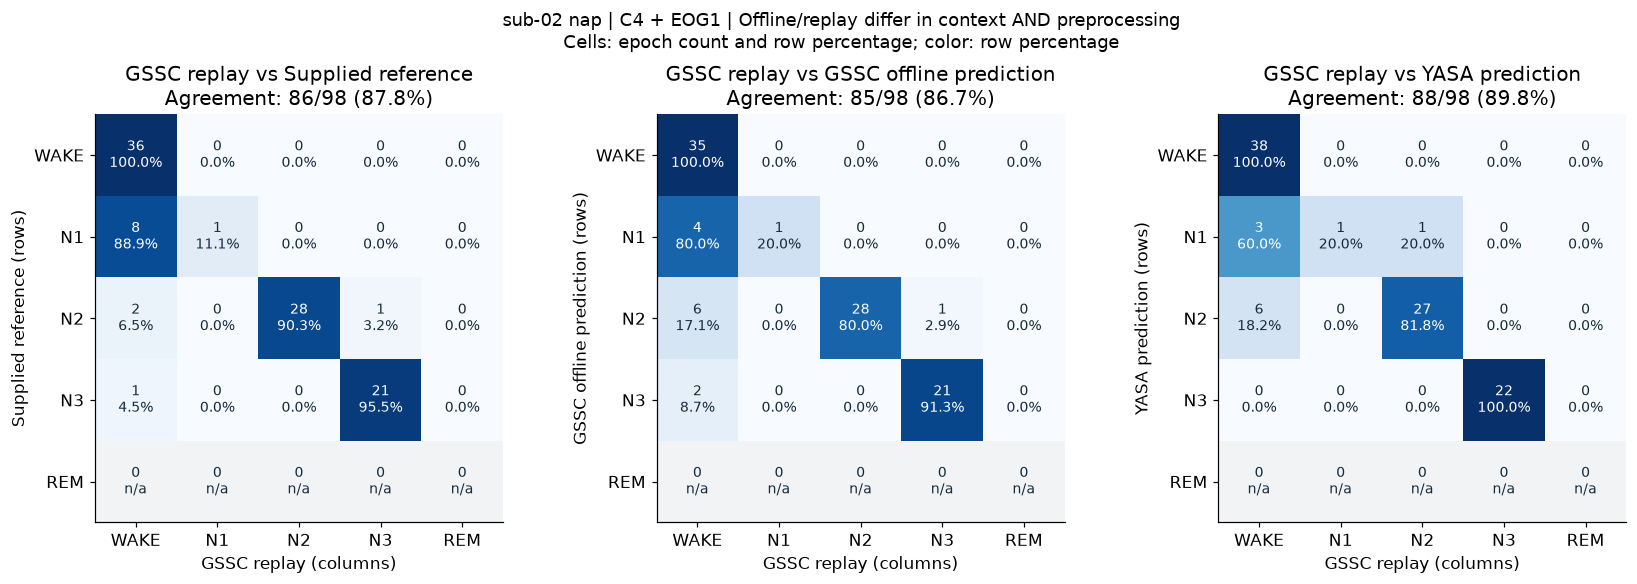

,Comparison,Matching_epochs,Total_epochs,Agreement_percent
0,GSSC offline vs reference,91,98,92.86
1,YASA vs reference,89,98,90.82
2,GSSC offline vs YASA,88,98,89.80
3,GSSC replay vs reference,86,98,87.76
4,GSSC replay vs offline,85,98,86.73
5,GSSC replay vs YASA,88,98,89.80


In [16]:
if RUN_REPLAY:
    assert np.array_equal(replay_table.Epoch.to_numpy(), table.Epoch.to_numpy())
    assert np.allclose(replay_table.Start_s, start_seconds)
    assert np.array_equal(replay_table.Reference.to_numpy(), reference)
    replay_predicted = replay_table.Predicted.to_numpy()
    replay_panels = [("Supplied reference", reference, "GSSC replay", replay_predicted),
                     ("GSSC offline prediction", predicted, "GSSC replay", replay_predicted)]
    if yasa_comparison is not None:
        replay_panels.append(("YASA prediction", yasa_predicted, "GSSC replay", replay_predicted))
    replay_confusions = plot_confusion_panels(
        replay_panels, OUT / "05_replay_confusion_matrices.png",
        note="sub-02 nap | C4 + EOG1 | Offline/replay differ in context AND preprocessing"
    )
    comparison_table["GSSC_replay"] = replay_predicted
    comparison_table.to_csv(OUT / "classifier_comparison.csv", index=False)
    replay_comparisons = [("GSSC replay vs reference", reference), ("GSSC replay vs offline", predicted)]
    if yasa_comparison is not None:
        replay_comparisons.append(("GSSC replay vs YASA", yasa_predicted))
    for name, left in replay_comparisons:
        matches = int(np.sum(left == replay_predicted))
        comparison_metrics.append({"Comparison": name, "Matching_epochs": matches,
                                   "Total_epochs": len(reference), "Agreement_percent": 100 * matches / len(reference)})
    pd.DataFrame(comparison_metrics).to_csv(OUT / "classifier_agreement.csv", index=False)
    display(pd.DataFrame(comparison_metrics).round(2))

## Take home
* GSSC classifies epochs; YASA can measure events in the recorded EEG offline.
* A model probability is not measured accuracy for that epoch.
* Record-based preprocessing and sequential preprocessing can yield different results.
* Validate nap staging and TIS-contaminated EEG before using predictions for control.

**Sources:** Hanna & Floel (2023), DOI 10.3389/fninf.2023.1086634;
https://github.com/jshanna100/gssc (AGPL-3.0).
Data: Vallat & Mallett, YASA sample dataset v1, Zenodo record 14564285.